# Piloto de aforo vehicular en Hoyos Rubio

Sube el CSV a la carpeta de trabajo de Colab antes de volver a ejecutar. El análisis usa ocho intervalos publicados del 12/09/2022 para el segmento 01 en sentido A. [Fuente primaria, Tabla 31](https://repositorio.unc.edu.pe/bitstream/handle/20.500.14074/6815/TESIS-CORREA%20PEREZ%20JEANMARCOS.pdf?isAllowed=y&sequence=1).

Total observado de 18:00 a 20:00: 1028 vehículos
Mayor intervalo de la muestra: 158 vehículos
Factor de hora pico de 07:15 a 08:15: 0.957


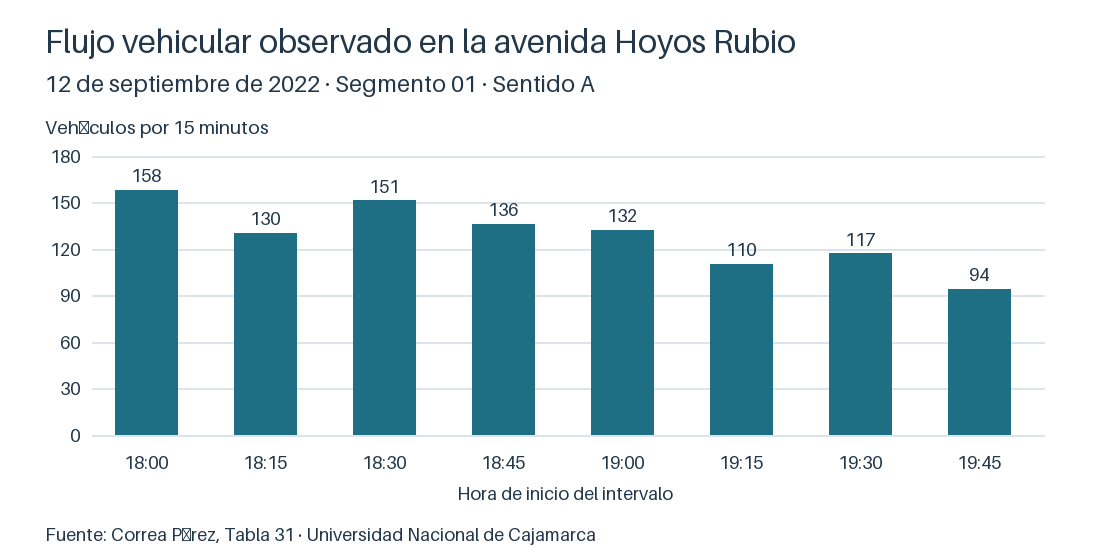

In [1]:
import csv
from pathlib import Path
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display

with Path('aforo_hoyos_rubio.csv').open(encoding='utf-8') as archivo:
    filas = list(csv.DictReader(archivo))
volumen = [int(fila['volumen']) for fila in filas]
assert len(volumen) == 8 and sum(volumen) == 1028
assert all(a['hora_fin'] == b['hora_inicio'] for a, b in zip(filas, filas[1:]))
print(f'Total observado de 18:00 a 20:00: {sum(volumen)} vehículos')
print(f'Mayor intervalo de la muestra: {max(volumen)} vehículos')
vhmd, q15 = 842, 220  # Valores publicados para la hora pico del estudio.
print(f'Factor de hora pico de 07:15 a 08:15: {vhmd / (4 * q15):.3f}')

imagen = Image.new('RGB', (1100, 560), '#ffffff')
dibujo = ImageDraw.Draw(imagen)
def rotulo(posicion, texto, tam=20, color='#23374a', ancla='lt'):
    dibujo.text(posicion, texto, font=ImageFont.load_default(size=tam), fill=color, anchor=ancla)

rotulo((45, 28), 'Flujo vehicular observado en la avenida Hoyos Rubio', 32)
rotulo((45, 75), '12 de septiembre de 2022 · Segmento 01 · Sentido A', 23)
rotulo((45, 120), 'Vehículos por 15 minutos', 19)
for marca in range(0, 181, 30):
    y = 435 - marca * 1.55
    dibujo.line((92, y, 1044, y), fill='#dce4eb', width=2)
    rotulo((80, y), str(marca), 18, ancla='rm')
for i, (fila, cantidad) in enumerate(zip(filas, volumen)):
    x = 146 + i * 119
    y = 435 - cantidad * 1.55
    dibujo.rectangle((x - 31, y, x + 31, 434), fill='#1e6f83')
    rotulo((x, y - 8), str(cantidad), 18, ancla='mb')
    rotulo((x, 456), fila['hora_inicio'], 18, ancla='mt')
rotulo((565, 486), 'Hora de inicio del intervalo', 18, ancla='mt')
rotulo((45, 527), 'Fuente: Correa Pérez, Tabla 31 · Universidad Nacional de Cajamarca', 18)
imagen.save('flujo_hoyos_rubio.png')
display(imagen)
